#Module 7 Assignment: Pima Indians Diabetes Classification

I selected the Pima Indians Diabetes dataset because it contains medical measurements and provides an opportunity to explore how classification models handle missing values, class imbalance, and prediction errors. I will first examine the dataset and visualize important patterns. Then, I will train a baseline Logistic Regression model, evaluate its performance, and explore whether feature selection, hyperparameter tuning, and an alternative Random Forest model can improve the results.

This notebook follows the general structure of the Module 7 Classification Model Pipeline notebook (DATA555, n.d.), with a few changes to make the evaluation more reliable. I used a stratified train/test split, handled missing values and feature scaling within a pipeline, and calculated AUC using predicted probabilities rather than predicted class labels. I also performed hyperparameter tuning using only the training data, so the pipeline and training-only tuning help prevent data leakage from the test set. Some steps (the pipeline, median imputation, feature selection and feature importances) use standard scikit-learn tools (Scikit-learn developers, n.d.-a, n.d.-b, n.d.-c, n.d.-d) that go beyond the module notebook, because the dataset has missing values and the assignment asks for feature selection. The data come from the Pima Indians Diabetes dataset.


# 1. Analyze the dataset(Part 1)


## 1.1 Load the data

In [1]:
# Load data
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"
df = pd.read_csv(url)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 1.2 Quality check

In [2]:
# Check missing values and duplicates
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())
df.describe().T

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Duplicates: 0


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [3]:
# Count hidden zeros and class balance
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print((df[zero_cols] == 0).sum())
print((df[zero_cols] == 0).mean().round(3))
print(df['Outcome'].value_counts(normalize=True))

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
Glucose          0.007
BloodPressure    0.046
SkinThickness    0.296
Insulin          0.487
BMI              0.014
dtype: float64
Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64


The dataset has 768 patients and 9 columns, with no NaN values and no duplicate rows. However, several columns contain zeros that are physiologically impossible: Insulin (374 zeros, 48.7%), SkinThickness (227, 29.6%), BloodPressure (35, 4.6%), BMI (11, 1.4%) and Glucose (5, 0.7%). These zeros likely represent missing measurements, so I will treat them as missing and impute them with the median inside the modelling pipeline. About 34.9% of patients have diabetes, so the classes are moderately imbalanced, and I will report precision, recall and F1 alongside accuracy.

## 1.3 Exploratory plots

# Plot 1: class balance

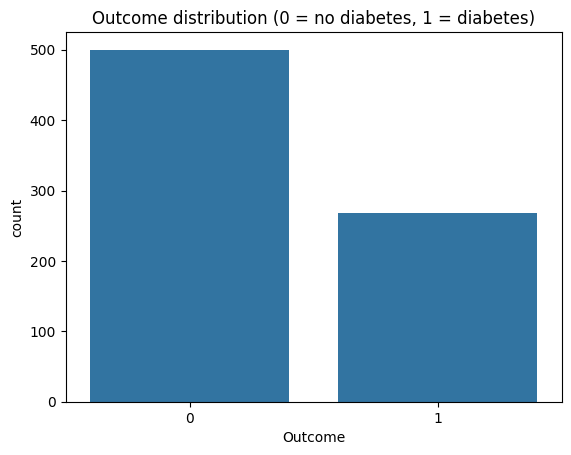

In [4]:
sns.countplot(data=df, x='Outcome')
plt.title('Outcome distribution (0 = no diabetes, 1 = diabetes)')
plt.show()

I used a count plot to examine the distribution of diabetic and non-diabetic patients in the dataset. The plot shows that about 65% of patients are non-diabetic and 35% are diabetic, meaning the classes are somewhat imbalanced. A model that always predicts “no diabetes” could achieve around 65% accuracy without identifying any diabetic patients. Therefore, I will also consider recall and F1 score when evaluating the model.

# Plot 2: histograms

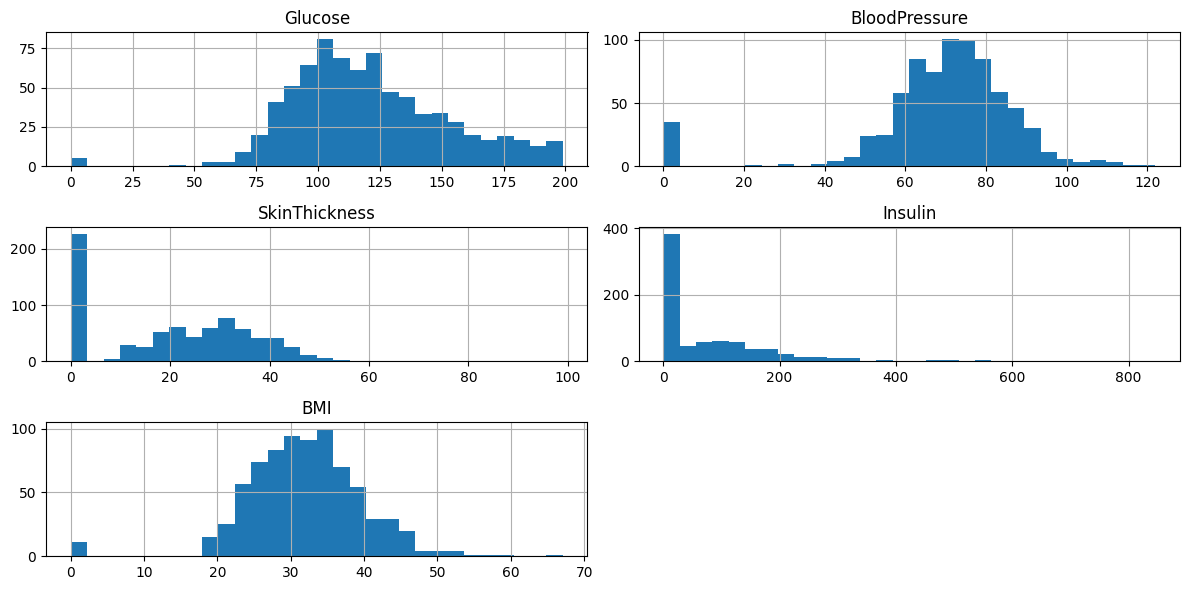

In [5]:
df[zero_cols].hist(bins=30, figsize=(12, 6))
plt.tight_layout()
plt.show()

I used histograms to examine the distribution of the medical measurements and identify unusual values. Insulin and SkinThickness have large spikes at zero, while Glucose, BloodPressure, and BMI have smaller spikes, suggesting that some measurements may be missing. I also noticed that some distributions are skewed, especially Insulin, so I will use median imputation instead of the mean because the median is less affected by extreme values.


# Convert impossible zeros to NaN

In [6]:
df[zero_cols] = df[zero_cols].replace(0, np.nan)
df[zero_cols].isna().sum()

,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


I noticed that zeros in these five medical measurements are not realistic, so I replaced them with NaN to mark them as missing values. I did not fill in the missing values at this stage because median imputation will be performed later inside the modelling pipeline, using the training data.

# Plot 3: box plots by outcome

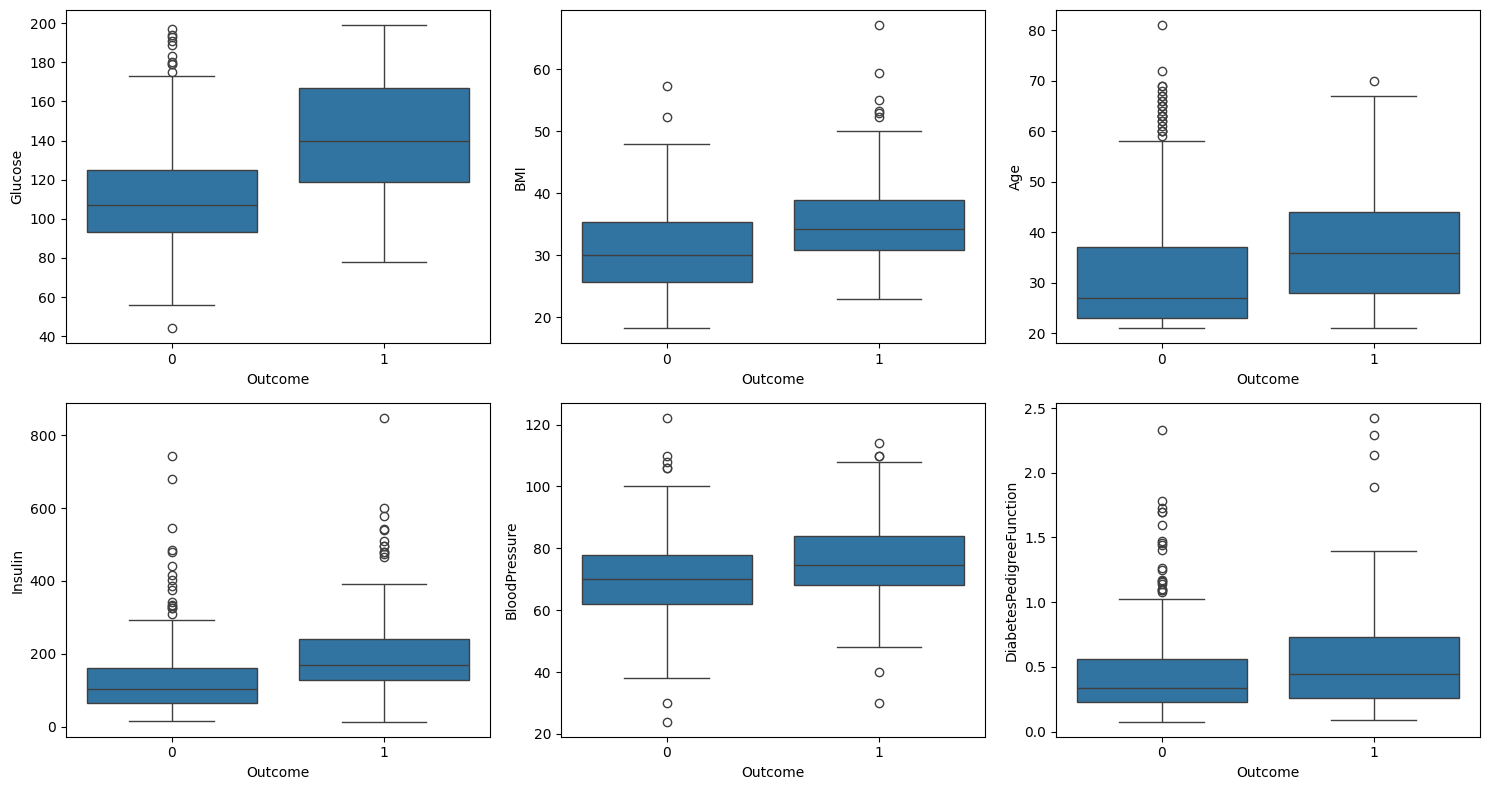

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, ['Glucose', 'BMI', 'Age', 'Insulin', 'BloodPressure', 'DiabetesPedigreeFunction']):
    sns.boxplot(data=df, x='Outcome', y=col, ax=ax)
plt.tight_layout()
plt.show()

I used box plots to compare the distribution of medical measurements between diabetic and non-diabetic patients and to identify possible outliers. Glucose shows the clearest difference, with a median of approximately 140 for diabetic patients compared with 107 for non-diabetic patients, although the distributions still overlap, while BloodPressure and DiabetesPedigreeFunction overlap much more and may be less useful on their own. Insulin and DiabetesPedigreeFunction also have many high outliers, which supports using the median for imputation and keeping extreme values in mind during modelling.

# Plot 4: correlation heatmap

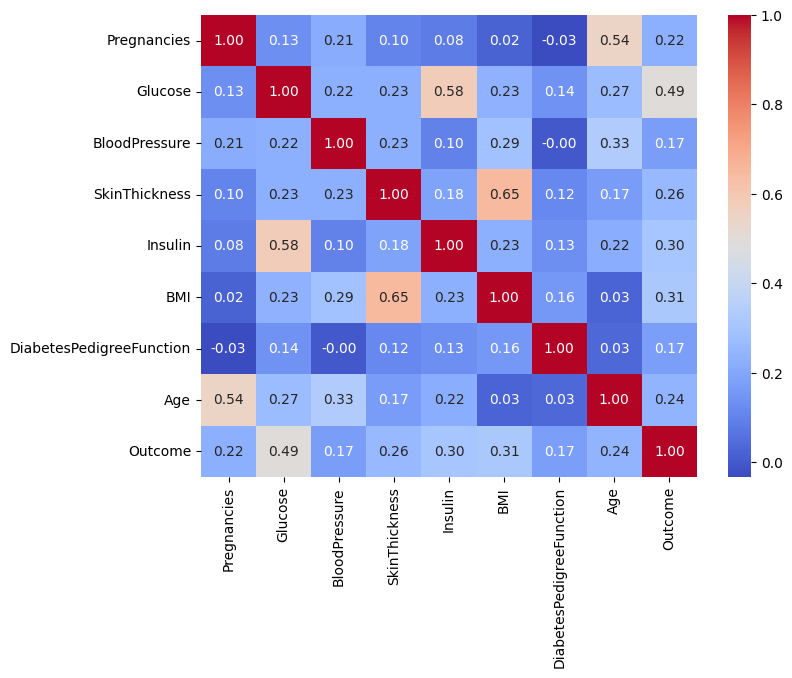

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

I used a correlation heatmap to examine how each feature relates to diabetes status and to the other features. Glucose has the strongest positive correlation with Outcome (0.49), while BloodPressure and DiabetesPedigreeFunction have much weaker correlations (around 0.17), which is consistent with the box plots. Some features are also correlated with each other, such as SkinThickness and BMI (0.65), Glucose and Insulin (0.58), and Age and Pregnancies (0.54), suggesting that they may contain overlapping information that could be considered during feature selection.

# 2. Train/test split ( part 2 )

## 2.1 Train/test split

In [9]:
# Split the data
from sklearn.model_selection import train_test_split

X = df.drop('Outcome', axis=1)
y = df['Outcome']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(614, 8) (154, 8)
0.349 0.351


Baseline classifier :
I split the dataset into 80% training data (614 patients) and 20% testing data (154 patients). I used `stratify=y` to keep the proportion of diabetic patients similar in both sets (about 35%) and `random_state=42` to make the results reproducible. Missing-value imputation and scaling will be fitted using only the training data to avoid data leakage from the test set.

## 2.2 Baseline model

              precision    recall  f1-score   support

 No diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



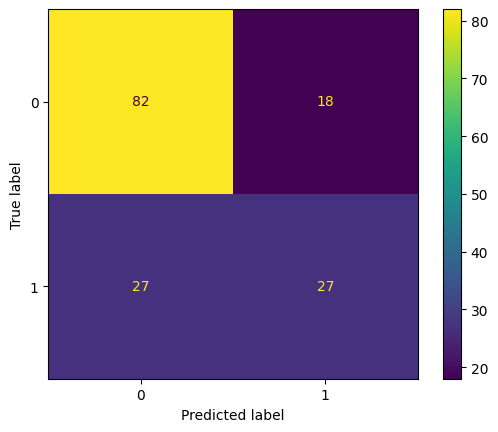

AUC: 0.812962962962963


In [10]:
# Train baseline logistic regression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)

baseline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000))
])
baseline.fit(X_train, y_train)
y_pred = baseline.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['No diabetes', 'Diabetes']))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()
print("AUC:", roc_auc_score(y_test, baseline.predict_proba(X_test)[:, 1]))

Baseline performance and limitations :
The baseline Logistic Regression model achieves 70.8% accuracy, only slightly higher than the 65% accuracy of always predicting “no diabetes.” For diabetic patients, precision is 0.60 and recall is 0.50, meaning the model misses 27 out of 54 diabetic patients in the test set, which is particularly concerning for diabetes screening. The model is also limited by the small test set, class imbalance, and missing measurements, although its AUC of 0.81 suggests that adjusting the decision threshold or improving the model may help identify more diabetic patients.

#Proposed improvements
I will (1) use feature selection to keep the most informative features, (2) tune the regularization strength and consider class weighting so the model catches more diabetic patients, and (3) try a Random Forest, which can capture non-linear relationships and interactions. Each change will be fit using cross-validation on the training set only, and I will report the effect on recall and F1 at every step.

# 3. Improve the model ( part 3)

In [11]:
# Set up model comparison
results = []
def evaluate(name, model):
    p = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    results.append({'Model': name,
                    'Accuracy': accuracy_score(y_test, p),
                    'Precision': precision_score(y_test, p),
                    'Recall': recall_score(y_test, p),
                    'F1': f1_score(y_test, p),
                    'AUC': roc_auc_score(y_test, prob)})
    return pd.DataFrame(results).round(3)

evaluate('1. Baseline logistic regression', baseline)

,Model,Accuracy,Precision,Recall,F1,AUC
0,1. Baseline logistic regression,0.708,0.6,0.5,0.545,0.813


## 3.1 Feature selection

In [12]:
# Find best number of features
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.feature_selection import SelectKBest, f_classif

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}
for k in range(3, 9):
    pipe = Pipeline([('impute', SimpleImputer(strategy='median')),
                     ('scale', StandardScaler()),
                     ('select', SelectKBest(f_classif, k=k)),
                     ('clf', LogisticRegression(max_iter=1000))])
    cv_scores[k] = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1').mean()
print({k: round(v, 3) for k, v in cv_scores.items()})
best_k = max(cv_scores, key=cv_scores.get)
print("Best k:", best_k)

{3: np.float64(0.641), 4: np.float64(0.636), 5: np.float64(0.641), 6: np.float64(0.65), 7: np.float64(0.652), 8: np.float64(0.655)}
Best k: 8


In [13]:
# Train feature selection model
fs_model = Pipeline([('impute', SimpleImputer(strategy='median')),
                     ('scale', StandardScaler()),
                     ('select', SelectKBest(f_classif, k=best_k)),
                     ('clf', LogisticRegression(max_iter=1000))]).fit(X_train, y_train)

kept = X.columns[fs_model.named_steps['select'].get_support()]
print("Kept:", list(kept))
evaluate('2. + Feature selection', fs_model)

Kept: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


,Model,Accuracy,Precision,Recall,F1,AUC
0,1. Baseline logistic regression,0.708,0.6,0.5,0.545,0.813
1,2. + Feature selection,0.708,0.6,0.5,0.545,0.813


I used SelectKBest with the ANOVA F-test to check whether selecting fewer features could improve the Logistic Regression model. I tested different numbers of features, from 3 to 8, using 5-fold cross-validation on the training data and compared their F1 scores. The cross-validation scores were very close, ranging from 0.636 to 0.655, with the highest score achieved when all 8 features were included.

This means that removing features did not improve the model's cross-validation performance, so I kept all 8 features. As a result, the model's performance on the test set remained the same as the baseline: 70.8% accuracy, 0.50 recall, and 0.545 F1 score. Although feature selection did not improve the results, it helped confirm that keeping all the available features was the best option among the feature counts tested.

In [14]:
# Feature scores from SelectKBest
selector = fs_model.named_steps['select']
scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
print(scores.round(1))

Glucose                     217.8
BMI                          74.2
Insulin                      39.4
Age                          37.6
SkinThickness                35.5
Pregnancies                  27.7
BloodPressure                21.3
DiabetesPedigreeFunction     17.2
dtype: float64


The F-scores support what I observed in Part 1: Glucose has the highest score (217.8), followed by BMI (74.2), while DiabetesPedigreeFunction (17.2) and BloodPressure (21.3) have the lowest scores. However, lower scores do not necessarily mean these features are unhelpful for prediction. Since removing features did not improve the cross-validation F1 score, I kept all 8 features.

In [15]:
# What happens if the weakest features are actually removed ?
rows = []
for k in [5, 6, 7, 8]:
    m = Pipeline([('impute', SimpleImputer(strategy='median')),
                  ('scale', StandardScaler()),
                  ('select', SelectKBest(f_classif, k=k)),
                  ('clf', LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
    p = m.predict(X_test)
    kept_k = X.columns[m.named_steps['select'].get_support()]
    rows.append({'k': k,
                 'Dropped': ', '.join(c for c in X.columns if c not in kept_k),
                 'CV F1': round(cv_scores[k], 3),
                 'Test recall': round(recall_score(y_test, p), 3),
                 'Test F1': round(f1_score(y_test, p), 3),
                 'Test AUC': round(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]), 3)})
pd.DataFrame(rows)

,k,Dropped,CV F1,Test recall,Test F1,Test AUC
0,5,"Pregnancies, BloodPressure, DiabetesPedigreeFu...",0.641,0.537,0.574,0.787
1,6,"BloodPressure, DiabetesPedigreeFunction",0.650,0.537,0.558,0.802
2,7,DiabetesPedigreeFunction,0.652,0.537,0.563,0.804
3,8,,0.655,0.500,0.545,0.813


To see what happens when features are removed, I compared models using 5 to 8 features on the test set. Removing BloodPressure and DiabetesPedigreeFunction (k = 6) slightly increased recall from 0.50 to 0.54 and F1 from 0.545 to 0.558, but AUC decreased from 0.813 to 0.802. Since these improvements were small and cross-validation showed the highest F1 score with all 8 features (0.655), I decided to keep all 8 features.

## 3.2 Hyperparameter tuning

In [16]:
# Tune logistic regression
from sklearn.model_selection import GridSearchCV
pipe = Pipeline([('impute', SimpleImputer(strategy='median')),
                 ('scale', StandardScaler()),
                 ('clf', LogisticRegression(solver='liblinear'))])
grid = {'clf__C': [0.01, 0.1, 1, 10, 100],
        'clf__penalty': ['l1', 'l2'],
        'clf__class_weight': [None, 'balanced']}
lr_search = GridSearchCV(pipe, grid, cv=cv, scoring='f1', n_jobs=-1).fit(X_train, y_train)
print(lr_search.best_params_, round(lr_search.best_score_, 3))
evaluate('3. Tuned logistic regression', lr_search.best_estimator_)

{'clf__C': 0.1, 'clf__class_weight': 'balanced', 'clf__penalty': 'l2'} 0.679


,Model,Accuracy,Precision,Recall,F1,AUC
0,1. Baseline logistic regression,0.708,0.600,0.500,0.545,0.813
1,2. + Feature selection,0.708,0.600,0.500,0.545,0.813
2,3. Tuned logistic regression,0.721,0.585,0.704,0.639,0.811


Hyperparameter tuning :
I used GridSearchCV with 5-fold cross-validation on the training data to find the best settings for Logistic Regression, using F1 score to compare the results. I tested different values of regularization strength (C), penalty types, and class weights. The best combination was C = 0.1, L2 penalty, and balanced class weights.

After tuning, recall increased from 0.50 to 0.70, meaning the model identified more diabetic patients than the baseline (38 out of 54 instead of 27). The F1 score also improved from 0.545 to 0.639, while precision decreased slightly from 0.60 to 0.585. Accuracy increased from 0.708 to 0.721, but AUC remained almost unchanged (0.813 to 0.811), suggesting that the improvement came mainly from identifying more patients as diabetic rather than improving how well the model ranked patients by risk.

The tuned model is better at identifying diabetic patients, but it also produces more false-positive predictions, with approximately 9 additional false alarms in exchange for identifying 11 more diabetic patients. Balanced class weights likely contributed to this change, although the improvement cannot be attributed to this setting alone because several hyperparameters were tuned together. For diabetes screening, this trade-off may be useful because missing someone who has diabetes can be more concerning than recommending further testing for someone who does not.



## 3.3 Alternative model: Random Forest

In [17]:
# Tune Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([('impute', SimpleImputer(strategy='median')),
                    ('clf', RandomForestClassifier(random_state=42))])
rf_grid = {'clf__n_estimators': [100, 300],
           'clf__max_depth': [3, 5, None],
           'clf__min_samples_leaf': [1, 3, 5],
           'clf__max_features': ['sqrt', 'log2'],
           'clf__class_weight': [None, 'balanced']}
rf_search = GridSearchCV(rf_pipe, rf_grid, cv=cv, scoring='f1', n_jobs=-1).fit(X_train, y_train)
print(rf_search.best_params_, round(rf_search.best_score_, 3))
evaluate('4. Tuned Random Forest', rf_search.best_estimator_)

{'clf__class_weight': 'balanced', 'clf__max_depth': 5, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 3, 'clf__n_estimators': 100} 0.705


,Model,Accuracy,Precision,Recall,F1,AUC
0,1. Baseline logistic regression,0.708,0.600,0.500,0.545,0.813
1,2. + Feature selection,0.708,0.600,0.500,0.545,0.813
2,3. Tuned logistic regression,0.721,0.585,0.704,0.639,0.811
3,4. Tuned Random Forest,0.727,0.591,0.722,0.650,0.818


Alternative model (Random Forest) :
I used Random Forest as an alternative classifier because it can capture non-linear relationships and interactions between features that Logistic Regression does not automatically model. I tuned the model using GridSearchCV with 5-fold cross-validation on the training data, comparing different numbers of trees, maximum depths, minimum leaf sizes, numbers of features considered at each split, and class weights. The best model used 100 trees, a maximum depth of 5, and balanced class weights.

On the test set, Random Forest achieved a recall of 0.722, an F1 score of 0.650, and an AUC of 0.818. These results were slightly better than the tuned Logistic Regression model, which achieved 0.704 recall, 0.639 F1, and 0.811 AUC. However, the improvement in recall means that Random Forest correctly identified only one additional diabetic patient out of 54, so the difference is too small to confidently conclude that it is the better model.

I would lean towards Random Forest because it achieved a slightly higher cross-validation F1 score (0.705 compared with 0.679 for tuned Logistic Regression). However, both models performed similarly, and Logistic Regression remains a reasonable alternative because it is simpler and easier to interpret. A larger test set or repeated cross-validation would help determine whether Random Forest consistently performs better.

## Feature importance

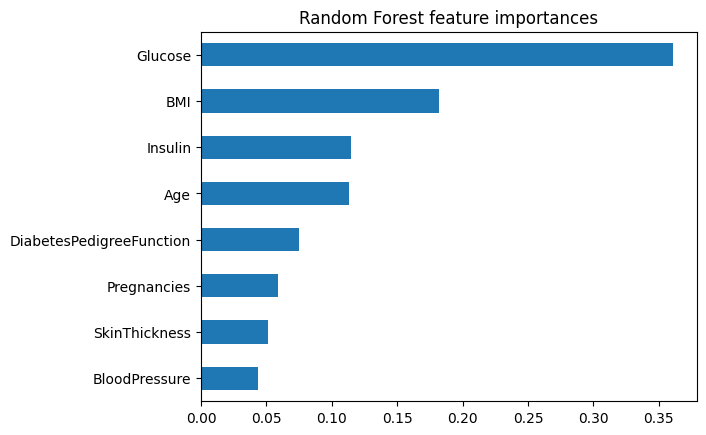

In [18]:
# Random Forest feature importances
rf_best = rf_search.best_estimator_.named_steps['clf']
importances = pd.Series(rf_best.feature_importances_, index=X.columns).sort_values()
importances.plot(kind='barh')
plt.title('Random Forest feature importances')
plt.show()

The Random Forest feature importance chart shows that Glucose is the most important feature (about 0.36), followed by BMI, Insulin, and Age. BloodPressure has the lowest importance (about 0.04). This is consistent with the box plots and correlation heatmap in Part 1, where Glucose showed the clearest relationship with diabetes status, while BloodPressure showed a weaker relationship.

The chart suggests that the Random Forest relies more heavily on Glucose and BMI when making predictions, while other features play smaller roles. In the earlier feature-selection step, cross-validation also showed that keeping all 8 features gave the highest F1 score for Logistic Regression. Therefore, I kept all 8 features in the models, although the importance chart alone does not prove that every feature is necessary.

## 3.4 Final comparison

In [19]:
# Show all results
pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,AUC
0,1. Baseline logistic regression,0.708,0.600,0.500,0.545,0.813
1,2. + Feature selection,0.708,0.600,0.500,0.545,0.813
2,3. Tuned logistic regression,0.721,0.585,0.704,0.639,0.811
3,4. Tuned Random Forest,0.727,0.591,0.722,0.650,0.818


###Confusion matrices for the three main models

In [20]:
# Compare confusion matrices
from sklearn.metrics import confusion_matrix
for name, m in [('Baseline', baseline),
                ('Tuned logistic regression', lr_search.best_estimator_),
                ('Tuned Random Forest', rf_search.best_estimator_)]:
    print(name)
    print(confusion_matrix(y_test, m.predict(X_test)), '\n')



Baseline
[[82 18]
 [27 27]] 

Tuned logistic regression
[[73 27]
 [16 38]] 

Tuned Random Forest
[[73 27]
 [15 39]] 



The confusion matrices show that tuning helped the model correctly identify 11 more diabetic patients (38 instead of 27), but also increased false positives by 9 (27 instead of 18). Random Forest identified one additional diabetic patient compared with tuned Logistic Regression (39 instead of 38), with the same number of false positives. This shows that hyperparameter tuning made the biggest improvement, while Random Forest provided only a small additional benefit.

#Overall summary :


The biggest improvement came from hyperparameter tuning, which increased recall from 0.50 to about 0.70 and F1 score from 0.545 to about 0.64, with a small decrease in precision. Balanced class weights likely contributed to this improvement by helping the model identify more diabetic patients, although other hyperparameters were also changed. Feature selection did not improve performance because the best result was obtained by keeping all 8 features.

Random Forest performed slightly better than tuned Logistic Regression, with recall increasing from 0.704 to 0.722 and F1 score from 0.639 to 0.650. However, this means only one additional diabetic patient was correctly identified in the test set, so the difference is too small to confidently conclude that Random Forest is better. I would lean towards Random Forest based on its slightly higher cross-validation F1 score, while recognizing that Logistic Regression is simpler and easier to interpret.

The main limitations are the small test set of 154 patients, the use of only one train/test split, and the large number of missing measurements in Insulin (about 49%) and SkinThickness (about 30%), which were handled using median imputation. The dataset also includes only women of Pima Indian heritage aged 21 or older, so the results may not generalize well to other populations. Using a larger and more diverse dataset and repeated cross-validation would help evaluate how reliably these models perform.

##References
DATA555. (n.d.). Module 7: Classification model pipeline [Google Colab notebook]. https://colab.research.google.com/drive/11i34g0jW8U_njPRJ8dPBYCN_Iw2oZI80?usp=sharing

npradaschnor. (n.d.). Pima-Indians-Diabetes-Dataset [Data set]. GitHub. https://github.com/npradaschnor/Pima-Indians-Diabetes-Dataset

Scikit-learn developers. (n.d.-a). Pipelines and composite estimators. scikit-learn. Retrieved October 12, 2026, from https://scikit-learn.org/stable/modules/compose.html

Scikit-learn developers. (n.d.-b). sklearn.ensemble.RandomForestClassifier. scikit-learn. Retrieved October 12, 2026, from https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

Scikit-learn developers. (n.d.-c). sklearn.feature_selection.SelectKBest. scikit-learn. Retrieved October 12, 2026, from https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html

Scikit-learn developers. (n.d.-d). sklearn.impute.SimpleImputer. scikit-learn. Retrieved October 12, 2026, from https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html

Blog post: “Hyperparameters for Classification Machine Learning Algorithms”
https://machinelearningmastery.com/hyperparameters-for-classification-machine-learning-algorithms/

videos
https://youtu.be/4jRBRDbJemM?si=tGcM1lpaCfwUs76I

